# Lab 2 — Leakage check
**Concepts:** 4 data leakage · 5 perceptual hash and Hamming distance.

**Leakage** means the test set contains (near-)copies of training images. A model can then "recognise"
test images instead of generalising, and the test score overstates real performance.

**Perceptual hash (pHash).** Shrink the image to 32×32, take its 2-D cosine transform (like JPEG does), keep
the 8×8 lowest-frequency coefficients, and write 1 where a coefficient is above their median, else 0.
Result: a 64-bit fingerprint of the coarse structure. Small edits (noise, slight contrast change) barely
change it. The **Hamming distance** between two fingerprints = number of differing bits:
0 = same picture, ≈ 32 = unrelated pictures.

In [1]:
# ---- Setup: identical in every notebook ------------------------------------
# Finds the project folder (Google Drive in Colab, or D:\weld_insp locally),
# makes src/ importable, fixes the random seed.
import os, sys
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    ROOT = Path("/content/drive/MyDrive/weld_insp")
else:
    ROOT = Path(os.environ.get("WELD_ROOT", Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()))
os.environ["WELD_ROOT"] = str(ROOT)
sys.path.insert(0, str(ROOT / "src"))
QUICK = os.environ.get("WELD_QUICK") == "1"   # tiny smoke-test mode, leave off for real runs

from weld_insp.config import get_paths, set_seed, CLASSES, SEED
P = get_paths()
P.show()
set_seed(SEED)

root          weld_insp
data          weld_insp/data
results       weld_insp/results
figures       weld_insp/results/figures
checkpoints   weld_insp/checkpoints
work          weld_insp/data
riawelc       weld_insp/data/riawelc
gdxray        weld_insp/data/gdxray
gdxray_crops  weld_insp/data/gdxray_crops


In [2]:
if IN_COLAB:
    !pip -q install imagehash
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from weld_insp.data import get_riawelc
from weld_insp.leakage import compute_phashes, nearest_hamming, leakage_table, hash_clusters, group_split, _popcount
RIA = get_riawelc(P)
table = pd.read_csv(P.results / "image_table.csv")
print(len(table), "images")

24407 images


## Task 1 — hash every image, find each test image's nearest training image

In [3]:
hashes = compute_phashes([RIA / p for p in table.path], cache=P.results / "phash.npy")
print(hashes.shape, hashes.dtype, "| example:", format(int(hashes[0]), "064b"))
idx = {s: np.where(table.split == s)[0] for s in ["train", "val", "test"]}

(24407,) uint64 | example: 1110011000011010000110110010110100011111011100000010110001101101


In [4]:
d_test, nn_test = nearest_hamming(hashes[idx["test"]], hashes[idx["train"]])
tab_test = leakage_table(d_test)
tab_test.insert(0, "comparison", "test vs train")
d_val, nn_val = nearest_hamming(hashes[idx["val"]], hashes[idx["train"]])
tab_val = leakage_table(d_val)
tab_val.insert(0, "comparison", "val vs train")
leak = pd.concat([tab_test, tab_val], ignore_index=True)
leak.to_csv(P.results / "leakage_table_original.csv", index=False)
leak

,comparison,threshold_bits,n_within,pct_within
0,test vs train,0,2443,100.00
1,test vs train,2,2443,100.00
2,test vs train,4,2443,100.00
3,test vs train,6,2443,100.00
4,test vs train,8,2443,100.00
5,val vs train,0,323,5.29
6,val vs train,2,856,14.03
7,val vs train,4,1340,21.96
8,val vs train,6,1687,27.65
9,val vs train,8,1948,31.93


100% of test images have a training image at distance 0. A hash of 0 means "same coarse picture", so we
check the actual file bytes (MD5 from Lab 1):

In [5]:
train_md5 = set(table.loc[idx["train"], "md5"])
test = table.loc[idx["test"]]
same_bytes = test.md5.isin(train_md5)
lab_of = table.loc[idx["train"]].drop_duplicates("md5").set_index("md5").label
print(f"Test images that are byte-identical copies of a training image: {same_bytes.sum()} of {len(test)}")
print(f"... and with the same label: {(test[same_bytes].md5.map(lab_of) == test[same_bytes].label).sum()}")
print(f"Validation images byte-identical to training: {table.loc[idx['val'], 'md5'].isin(train_md5).sum()}")
print(f"Validation radiograph sections also in train: "
      f"{len(set(table.loc[idx['val'], 'radiograph']) & set(table.loc[idx['train'], 'radiograph']))} of "
      f"{table.loc[idx['val'], 'radiograph'].nunique()}")

Test images that are byte-identical copies of a training image: 2443 of 2443
... and with the same label: 2443
Validation images byte-identical to training: 0
Validation radiograph sections also in train: 107 of 107


## Task 2 — look at the closest pairs

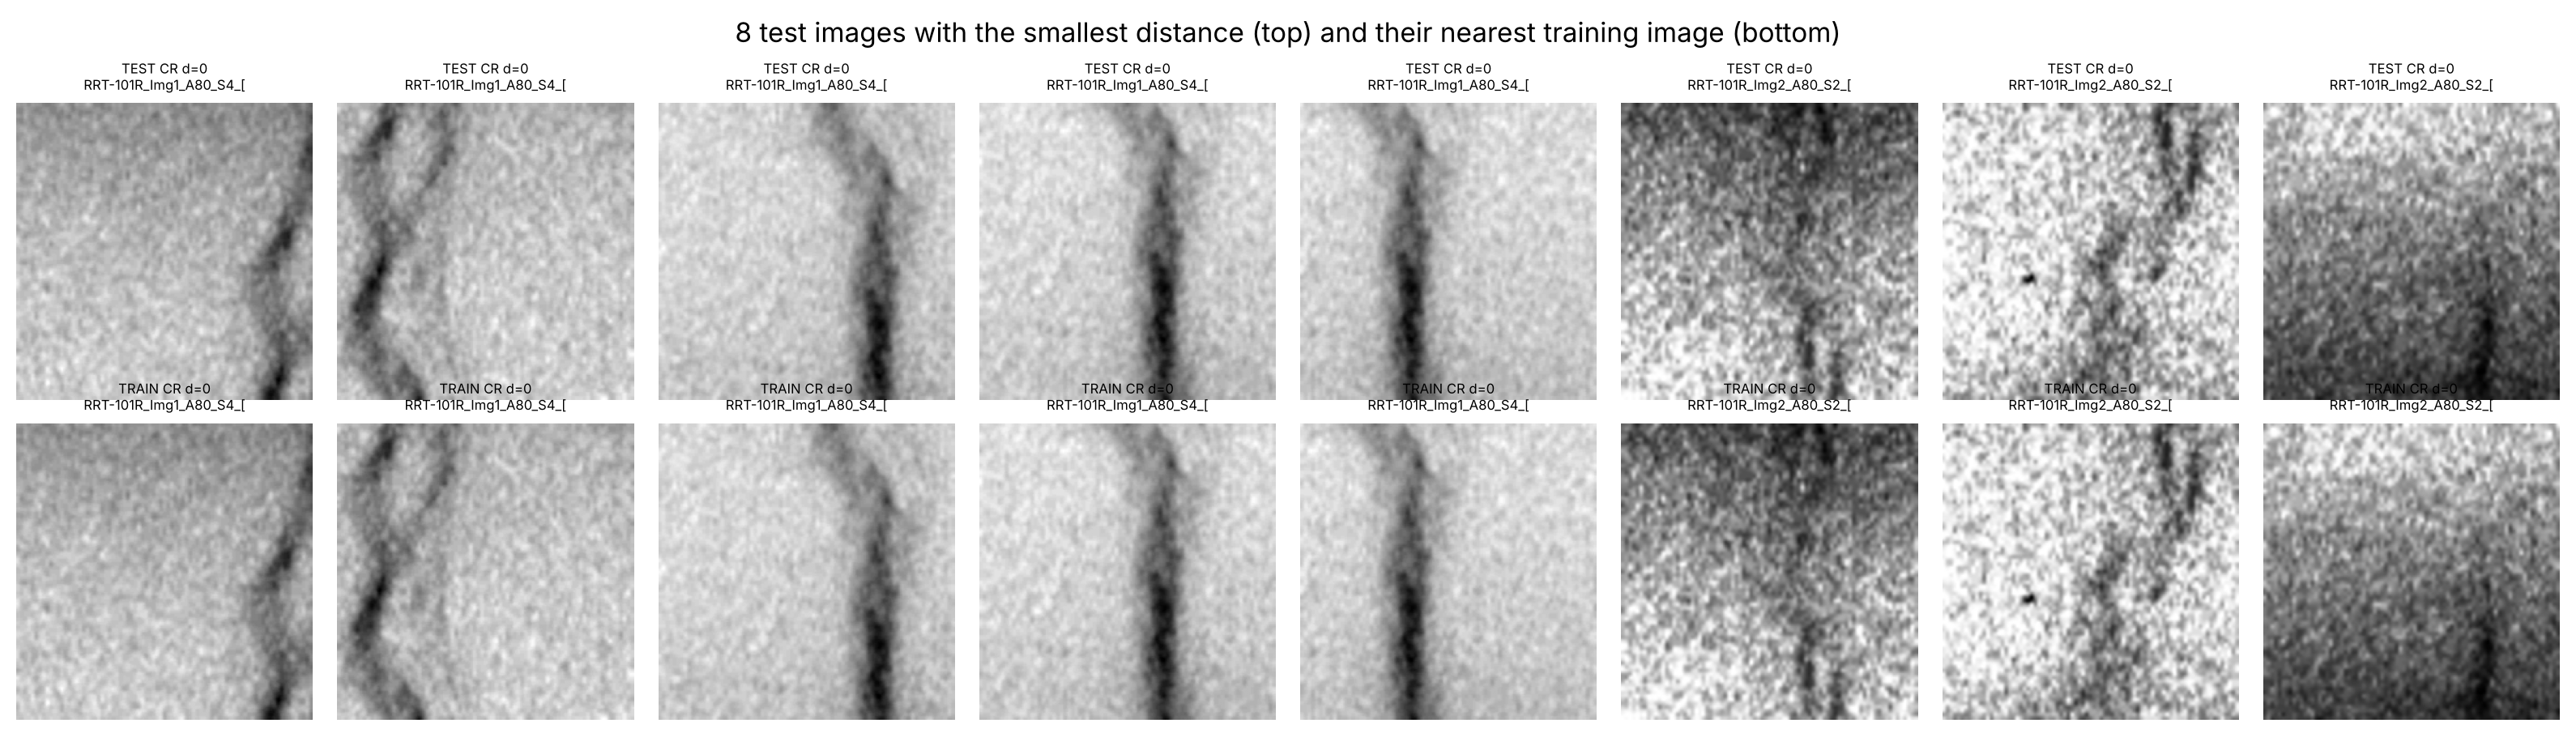

In [6]:
order = np.argsort(d_test, kind="stable")[:8]
fig, ax = plt.subplots(2, 8, figsize=(16, 4.6))
for k, j in enumerate(order):
    a, b = table.iloc[idx["test"][j]], table.iloc[idx["train"][nn_test[j]]]
    for r, (row, tag) in enumerate([(a, "TEST"), (b, "TRAIN")]):
        ax[r, k].imshow(plt.imread(RIA / row.path), cmap="gray"); ax[r, k].axis("off")
        ax[r, k].set_title(f"{tag} {row.label} d={d_test[j]}\n{row.file[:22]}", fontsize=6)
plt.suptitle("8 test images with the smallest distance (top) and their nearest training image (bottom)")
plt.tight_layout(); plt.savefig(P.figures / "02_closest_test_train_pairs.png", dpi=130); plt.show()

In [7]:
top50 = np.argsort(d_test, kind="stable")[:50]
same = (table.label.values[idx["test"][top50]] == table.label.values[idx["train"][nn_test[top50]]]).sum()
print(f"Top 50 closest test-train pairs sharing a label: {same} / 50")
v = d_val <= 6
print(f"Val-train pairs within 6 bits sharing a label: "
      f"{(table.label.values[idx['val'][v]] == table.label.values[idx['train'][nn_val[v]]]).mean():.1%} of {v.sum()}")

Top 50 closest test-train pairs sharing a label: 50 / 50
Val-train pairs within 6 bits sharing a label: 99.6% of 1687


Because every test pair is an exact copy, the test set cannot show what non-identical pairs look like.
To **choose a threshold** we look at validation-vs-train pairs at increasing distances instead.

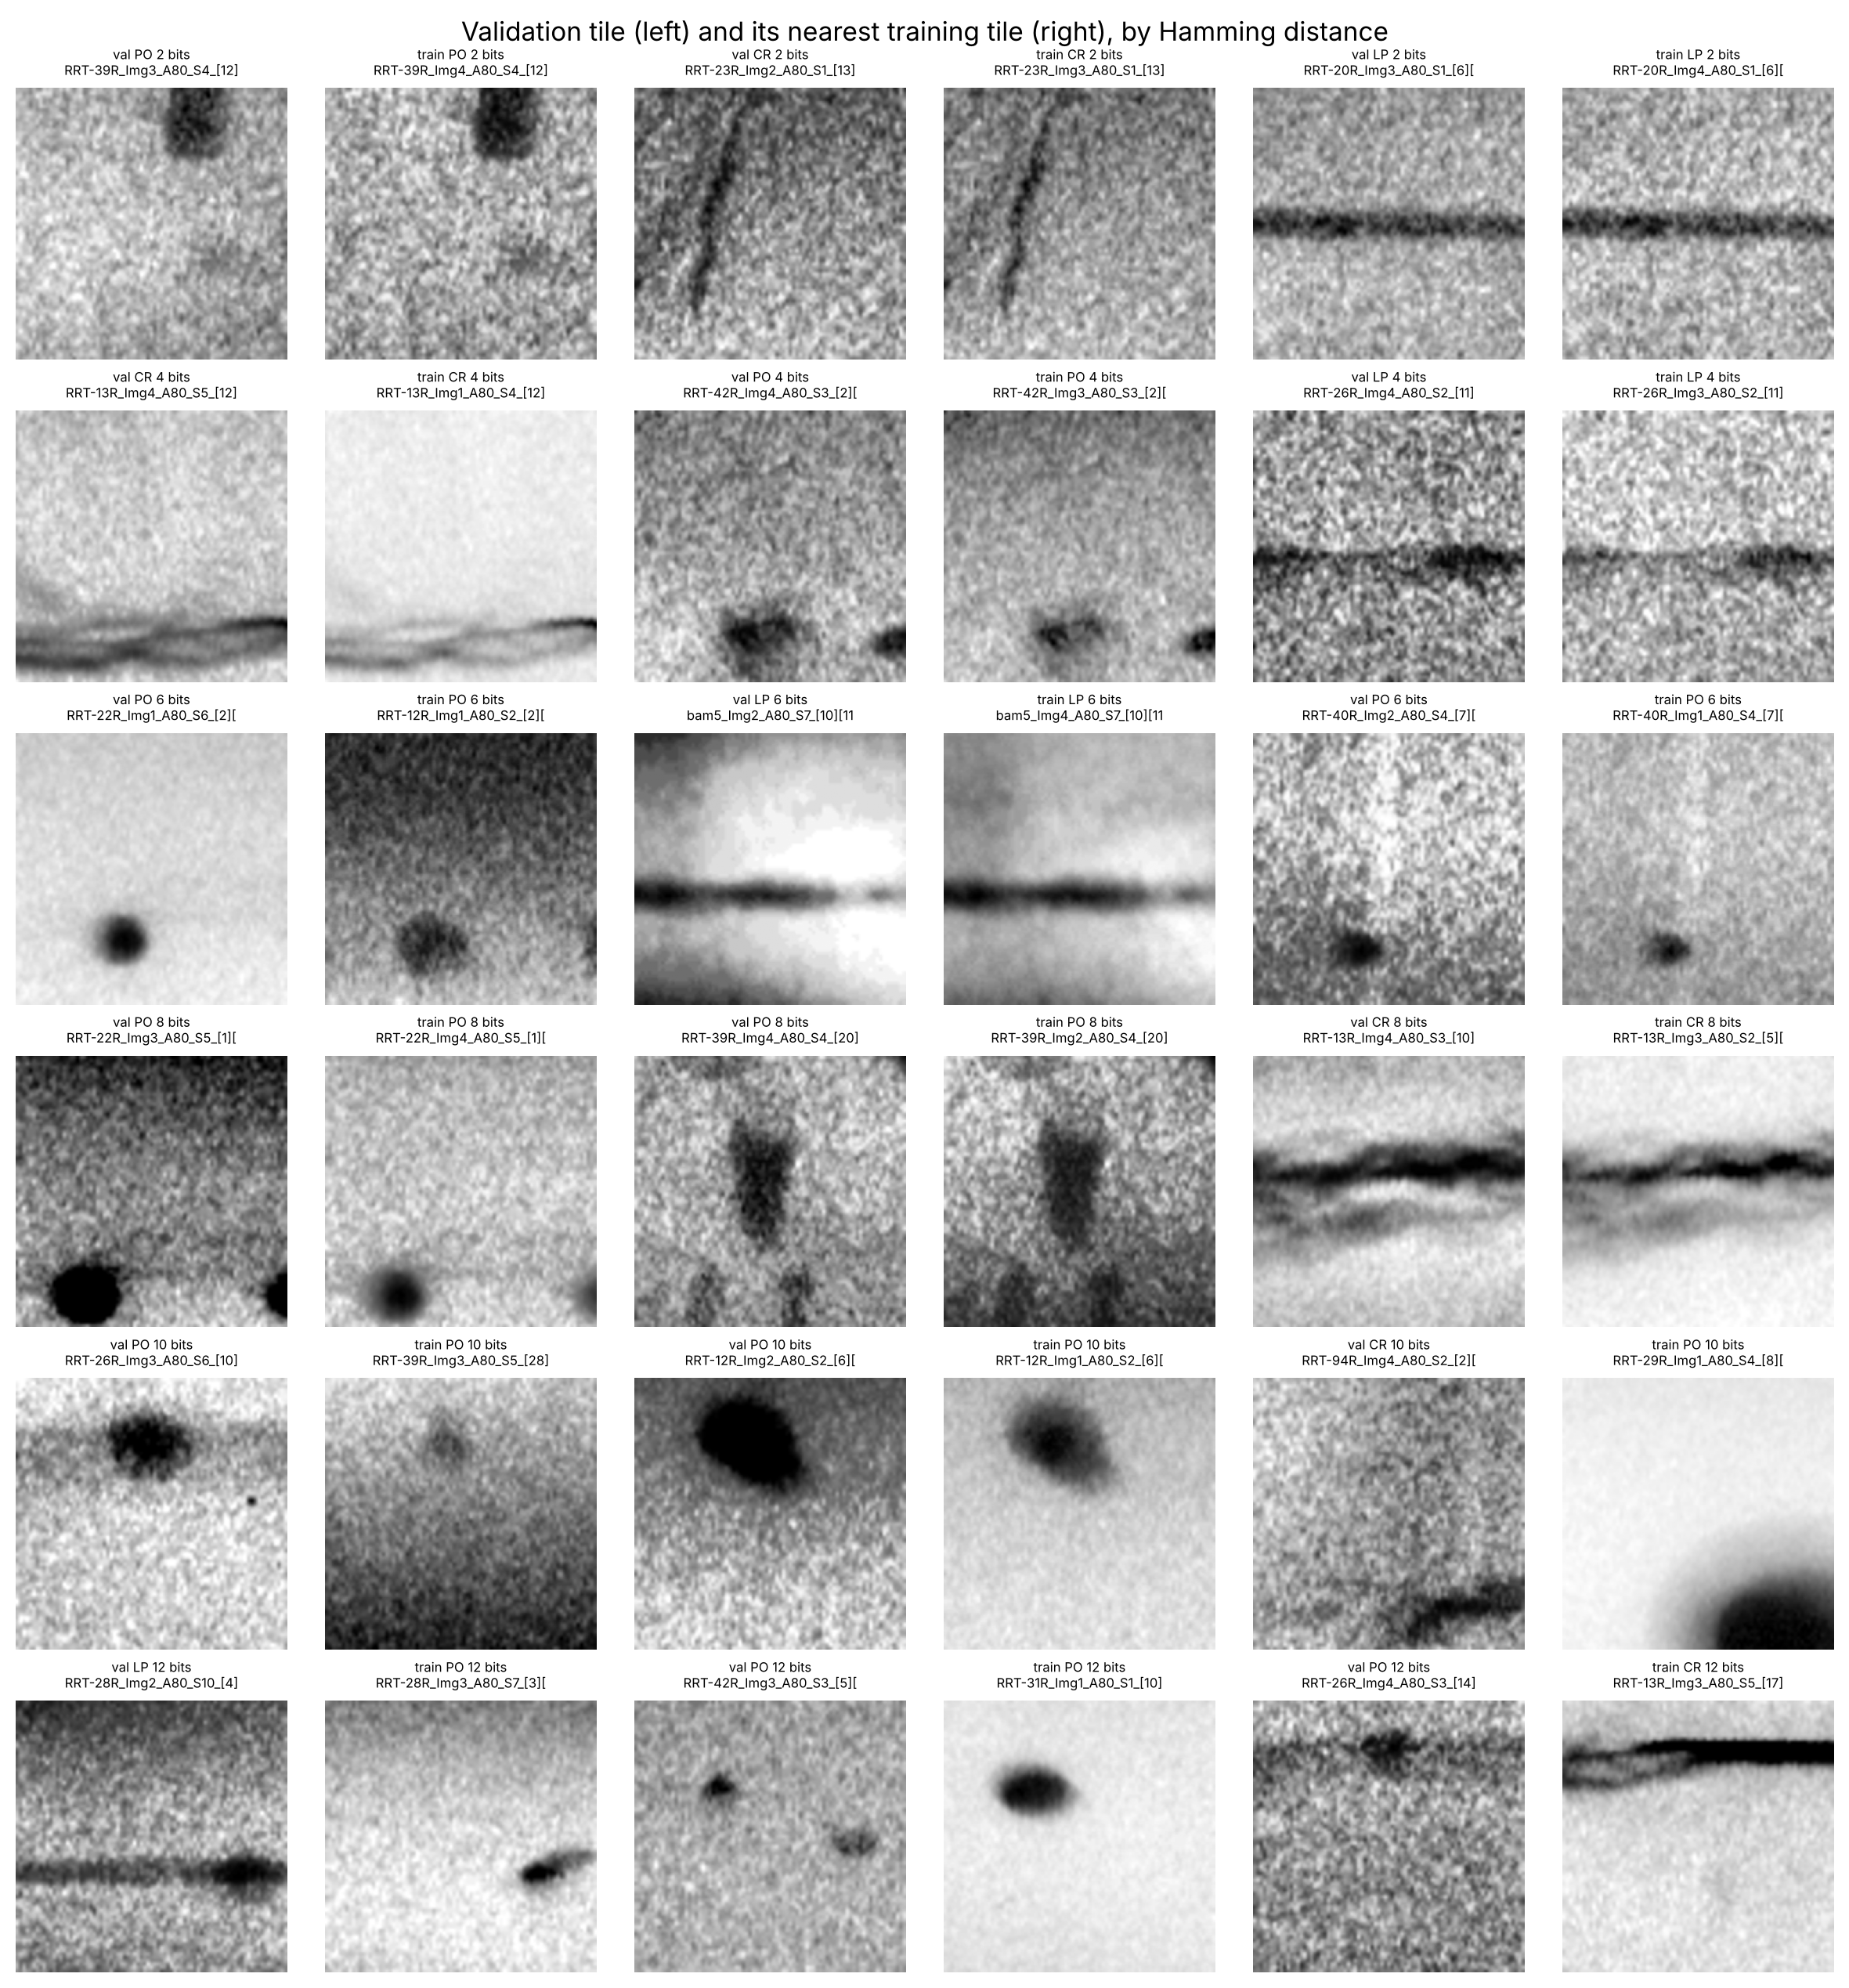

In [8]:
rng = np.random.default_rng(SEED)
dists = [2, 4, 6, 8, 10, 12]
fig, ax = plt.subplots(len(dists), 6, figsize=(12, 2.15 * len(dists)))
for r, dist in enumerate(dists):
    cand = np.where(d_val == dist)[0]
    for k, j in enumerate(rng.choice(cand, 3, replace=False)):
        a, b = table.iloc[idx["val"][j]], table.iloc[idx["train"][nn_val[j]]]
        for m, (row, tag) in enumerate([(a, "val"), (b, "train")]):
            x = ax[r, 2 * k + m]; x.imshow(plt.imread(RIA / row.path), cmap="gray"); x.axis("off")
            x.set_title(f"{tag} {row.label} {dist} bits\n{row.file[:24]}", fontsize=6)
plt.suptitle("Validation tile (left) and its nearest training tile (right), by Hamming distance")
plt.tight_layout(); plt.savefig(P.figures / "02_pairs_by_distance.png", dpi=110); plt.show()

**Threshold: 6 bits.** Up to 6 bits, the pairs are the *same physical defect*: same plate, same grid position,
but a different section (e.g. `RRT-39R_Img2 … [7]` and `RRT-39R_Img4 … [7]`), so the `Img1–4` sections are
repeated scans of the same film region. From 8 bits on, pairs start to come from *different* plates that only
look alike. Note that even at 10–12 bits some pairs are still the same pores or crack, so pHash alone
under-counts leakage. File names give a stronger rule: **group by plate**.

**Verdict: leakage is high.** The official test set is 100% byte-identical copies of training images with the
same labels, and 28% of validation tiles have a same-defect twin in training. The ~99% published scores on this
split therefore measure memorisation of the training tiles, not the ability to classify a new radiograph.

## Task 3 — build a leakage-free split
1. Drop the 2,443 exact copies (keep one copy of each file).
2. Link images within 6 bits (pHash clusters), and check whether those links cross plates.
3. Assign whole plates to train / val / test, ≈ 70 : 15 : 15 per class.

In [9]:
uniq = table.drop_duplicates("md5").reset_index(drop=True)
h_u = hashes[~table.duplicated("md5").values]
print(f"{len(uniq):,} unique images (removed {len(table) - len(uniq):,} copies)")
clusters = hash_clusters(h_u, threshold=6)
cl = pd.DataFrame({"cluster": clusters, "plate": uniq.plate, "label": uniq.label})
span = cl.groupby("cluster").plate.nunique()
print(f"{cl.cluster.nunique():,} pHash clusters; {int((span > 1).sum())} of them span more than one plate")

21,964 unique images (removed 2,443 copies)


17,614 pHash clusters; 105 of them span more than one plate


394 cross-plate pairs within 6 bits; labels:
col_0  LP  ND   PO
row_0             
LP      0   0    3
PO      9   1  381


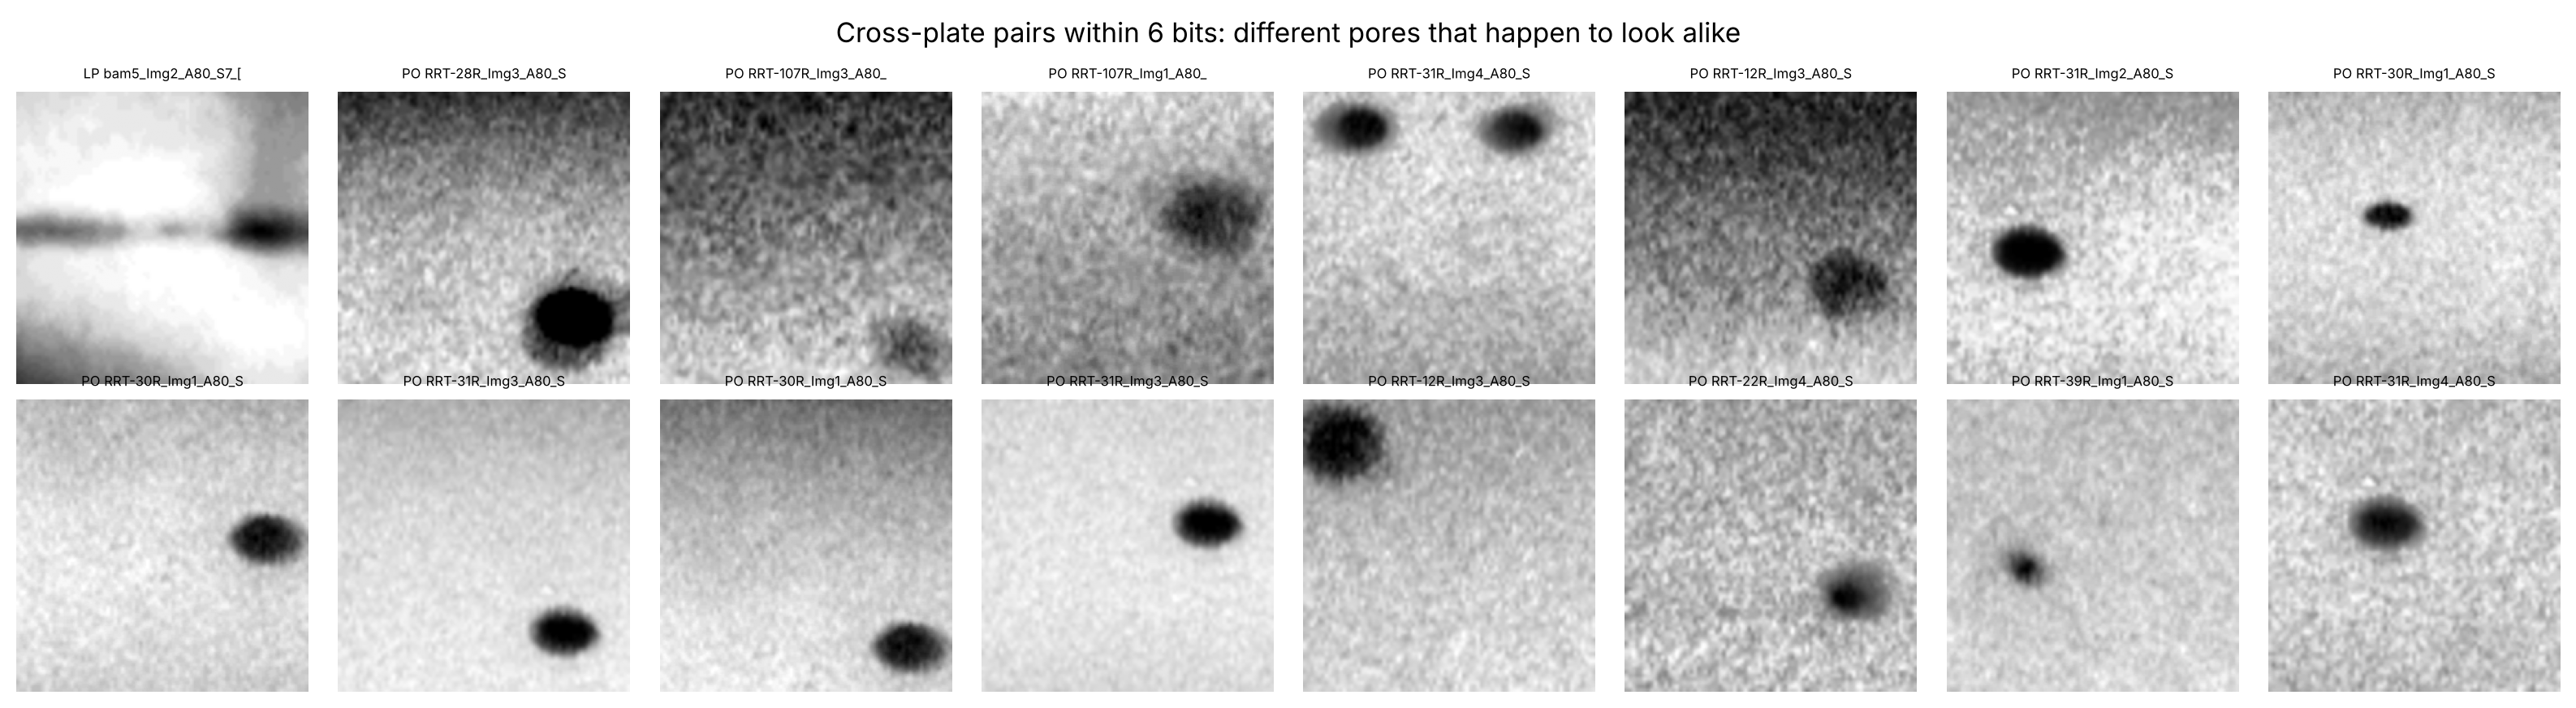

In [10]:
# What do the cross-plate links look like?
pl = uniq.plate.values; pairs = []
for s in range(0, len(h_u), 1024):
    d = _popcount(h_u[s:s + 1024, None] ^ h_u[None, :])
    for a, b in zip(*np.nonzero(d <= 6)):
        a += s
        if a < b and pl[a] != pl[b]:
            pairs.append((a, b, int(d[a - s, b])))
pairs = pd.DataFrame(pairs, columns=["a", "b", "dist"])
print(len(pairs), "cross-plate pairs within 6 bits; labels:")
print(pd.crosstab(uniq.label.values[pairs.a], uniq.label.values[pairs.b]))
fig, ax = plt.subplots(2, 8, figsize=(16, 4.4))
for k, j in enumerate(np.random.default_rng(1).choice(len(pairs), 8, replace=False)):
    for r, i in enumerate(pairs.iloc[j][["a", "b"]]):
        row = uniq.iloc[i]; ax[r, k].imshow(plt.imread(RIA / row.path), cmap="gray"); ax[r, k].axis("off")
        ax[r, k].set_title(f"{row.label} {row.file[:18]}", fontsize=6)
plt.suptitle("Cross-plate pairs within 6 bits: different pores that happen to look alike")
plt.tight_layout(); plt.savefig(P.figures / "02_cross_plate_lookalikes.png", dpi=110); plt.show()

The cross-plate links are almost all **porosity tiles with a single round pore in a similar spot**: different
pores on different plates, which pHash's 64 bits cannot tell apart. If we let these links merge groups, they
chain 17 plates into one 16,000-image group and no split is possible. So the grouping key is the **plate**:
it contains every genuine same-defect pair seen above, and the look-alikes are left as they are (they are
not copies of each other).

In [11]:
uniq["split_original"] = uniq["split"]
uniq["split"] = group_split(uniq, group_col="plate", fractions=(0.70, 0.15, 0.15), seed=SEED)
uniq.to_csv(P.results / "clean_split.csv", index=False)
clean_counts = pd.crosstab(uniq.label, uniq.split, margins=True, margins_name="total")
clean_counts = clean_counts.loc[["CR", "PO", "LP", "ND", "total"], ["train", "val", "test", "total"]]
clean_counts.to_csv(P.results / "class_counts_clean.csv")
print("Plates per split:", uniq.groupby("split").plate.nunique().to_dict())
clean_counts

group_split: mean relative error per class/split = 0.044
Plates per split: {'test': 6, 'train': 19, 'val': 4}


split,train,val,test,total
label,,,,
CR,4943,977,950,6870
PO,4016,841,831,5688
LP,2680,626,700,4006
ND,3730,852,818,5400
total,15369,3296,3299,21964


In [12]:
(pd.crosstab(uniq.label, uniq.split, normalize="index") * 100).round(1).loc[["CR", "PO", "LP", "ND"], ["train", "val", "test"]]

split,train,val,test
label,,,
CR,72.0,14.2,13.8
PO,70.6,14.8,14.6
LP,66.9,15.6,17.5
ND,69.1,15.8,15.1


In [13]:
# Re-check leakage on the clean split
hc = h_u
ci = {s: np.where(uniq.split == s)[0] for s in ["train", "val", "test"]}
rows = []
for s in ["test", "val"]:
    d, _ = nearest_hamming(hc[ci[s]], hc[ci["train"]])
    t = leakage_table(d); t.insert(0, "comparison", f"{s} vs train (clean)"); rows.append(t)
leak_clean = pd.concat(rows, ignore_index=True)
leak_clean.to_csv(P.results / "leakage_table_clean.csv", index=False)
assert not set(uniq[uniq.split == "test"].plate) & set(uniq[uniq.split == "train"].plate)
leak_clean

,comparison,threshold_bits,n_within,pct_within
0,test vs train (clean),0,1,0.03
1,test vs train (clean),2,8,0.24
2,test vs train (clean),4,19,0.58
3,test vs train (clean),6,61,1.85
4,test vs train (clean),8,126,3.82
5,val vs train (clean),0,0,0.00
6,val vs train (clean),2,5,0.15
7,val vs train (clean),4,15,0.46
8,val vs train (clean),6,56,1.70
9,val vs train (clean),8,148,4.49


On the clean split no plate is shared between splits, and only ~2% of test tiles have a training tile within
6 bits (the look-alike pores). Every later lab trains on `clean_split.csv` and, where the task sheet asks, also
reports the original split so the effect of leakage is visible in the numbers.

## Notes
- **Did:** hashed all 24,407 tiles (pHash, 64 bits), measured nearest-neighbour distances test→train and val→train, looked at pairs by distance, and built a plate-grouped 70/15/15 split (`clean_split.csv`, 21,964 unique tiles, 29 plates).
- **Found:** the official RIAWELC test set is 2,443 byte-identical copies of training tiles (100%, same labels); 28% of validation tiles have a same-defect twin in training within 6 bits. Leakage is high.
- **Found:** the `Img1–Img4` sections of a plate are repeat scans of the same film, so the only safe grouping is by plate.
- **Surprised me:** pHash links different pores on different plates (single round blobs look alike), so blind clustering would merge most of the dataset; the file-name plate ID was the better tool.